# Introdução ao Aprendizado de Máquina com Dados Textuais

**Foco:** Classificação supervisionada de textos clínicos com **Scikit-Learn**.

---
## Contexto da trilha

No curso anterior, trabalhamos com **Pandas para preparar e explorar dados textuais**.  
Agora vamos dar o próximo passo: **treinar um modelo de Machine Learning** para classificar automaticamente a gravidade de prontuários ambulatoriais em:

- **verde**
- **amarelo**
- **vermelho**

Este notebook foi adaptado para a realidade do novo dataset sintético de prontuários.


## 1. O cenário

Imagine que um ambulatório recebe muitos registros textuais todos os dias.  
Cada prontuário contém uma descrição breve do caso e já foi classificado manualmente pela equipe em uma categoria de gravidade.

Nosso objetivo agora é construir uma IA que aprenda com esses exemplos e consiga sugerir automaticamente a categoria de novos textos.


## 2. A missão

Vamos construir um pipeline simples de classificação textual:

1. carregar o dataset;
2. inspecionar os dados;
3. separar treino e teste;
4. transformar texto em números;
5. treinar um classificador;
6. avaliar o desempenho;
7. interpretar os resultados.

> Em Machine Learning com texto, o ponto central é este:  
> **o algoritmo não lê palavras como humanos; ele precisa de uma representação numérica do texto.**


## 3. Dicionário de dados

O dataset possui as seguintes colunas:

- **id**: identificador do registro;
- **texto**: prontuário clínico sintético;
- **categoria**: classe alvo da gravidade (`verde`, `amarelo`, `vermelho`).

Neste notebook:
- `X` será a coluna **texto**
- `y` será a coluna **categoria**


## 4. Recurso-chave: Scikit-Learn

Usaremos a biblioteca **Scikit-Learn**, muito usada em problemas clássicos de Machine Learning.

Ela nos ajudará em três partes:
- divisão treino/teste;
- transformação de texto em vetores;
- treinamento e avaliação do classificador.


# Notebook Hands-on: Classificando prontuários clínicos com IA


## Passo 1 — Setup e carregamento dos dados

Vamos importar as bibliotecas e carregar o dataset sintético de prontuários.


In [ ]:
import pandas as pd

pd.set_option("display.max_colwidth", 220)

# Carregamento do dataset
df = pd.read_csv("SimSUM.csv", encoding="utf-8")

print("✅ Dataset carregado com sucesso!")
df.head()


✅ Dataset carregado com sucesso!


,Unnamed: 0,policy,self_empl,asthma,smoking,COPD,season,hay_fever,pneu,common_cold,dysp,cough,pain,fever,nasal,antibiotics,days_at_home,text,advanced_text
0,0,yes,no,no,no,no,summer,no,no,no,no,no,no,high,no,yes,2,"**History**\nPatient reports a significant increase in body temperature over the last 48 hours, exceeding normal ranges, indicating a high fever. There have been no respiratory symptoms such as pain, dyspnea, or coug...","**History**\nPt reports high fever for 48 hrs, denies resp pain, dyspnea, or cough. Describes significant fatigue and malaise. No recent routine changes or known infectious exposures. Discusses recent stress and trav..."
1,1,yes,no,no,no,no,summer,no,no,no,no,no,no,none,no,no,2,"**History**\nThe patient reports a gradual onset of fatigue over the past month without any noticeable triggers. Additionally, they describe experiencing intermittent headaches that are relieved with over-the-counter...","**History**\nPt reports gradual onset of fatigue over past month, with intermittent HAs relieved by OTC analgesics. Variable sleep quality, tiredness on waking. No dietary changes, recent travel, appetite loss, or si..."
2,2,yes,no,no,no,no,summer,no,no,no,no,no,no,low,no,no,3,**History**\nThe patient reports no issues with shortness of breath or any persistent or acute cough. The patient states feeling generally well and does not mention experiencing any related upper respiratory symptoms...,"**History**\nPt denies SOB or cough. Reports feeling well overall, w/ no upper resp symptoms. Exercise tolerance normal, engages in daily activities w/o limitations. No recent changes in sleeping/eating patterns, den..."
3,3,no,yes,no,no,no,summer,yes,no,no,no,no,no,low,yes,no,2,"**History**\nPatient presents with low-grade fever and significant nasal symptoms, including congestion and runny nose. No respiratory pain, dyspnea, or cough reported. Known condition of hay fever, which the patient...","**History**\nPt presents with low-grade fever and nasal sx (congestion, rhinorrhea). No respiratory pain, dyspnea, or cough. Hx of hay fever, typically seasonal. Fever began 2 days ago; nasal sx persists for 3 days. ..."
4,4,yes,no,no,no,no,winter,no,no,no,no,no,no,none,no,no,1,**History**\nThe patient indicates experiencing episodic dizziness primarily when standing quickly or after prolonged periods of sitting. There is no history of recent injuries or illnesses. They mentioned an increas...,"**History**\nPt reports episodic dizziness esp. when standing quickly or post prolonged sitting. No Hx of recent injuries or illnesses. Increase in workload noted. No vision or balance disturbances, no previous simil..."


## Passo 2 — Exploração inicial

Antes de treinar qualquer modelo, precisamos conhecer o dataset.


In [ ]:
print("Dimensão do dataset:", df.shape)
print("\nTipos de dados:")
print(df.dtypes)

Dimensão do dataset: (10000, 19)

Tipos de dados:
Unnamed: 0        int64
policy           object
self_empl        object
asthma           object
smoking          object
COPD             object
season           object
hay_fever        object
pneu             object
common_cold      object
dysp             object
cough            object
pain             object
fever            object
nasal            object
antibiotics      object
days_at_home      int64
text             object
advanced_text    object
dtype: object


In [ ]:
df["common_cold"].value_counts()


,count
common_cold,
no,7665
yes,2335


In [ ]:
df["common_cold"].value_counts(normalize=True).mul(100).round(2)


,proportion
common_cold,
no,76.65
yes,23.35


In [ ]:
for cat in ["yes", "no"]:
    print("=" * 100)
    print(f"CLASSE: {cat.upper()}")
    exemplos = df.loc[df["common_cold"] == cat, "advanced_text"].head(2).tolist()
    for i, texto in enumerate(exemplos, start=1):
        print(f"\nExemplo {i}: {texto}")


CLASSE: YES

Exemplo 1: **History**
Pt reports light resp pain for past 3 days, consistent but not debilitating. Describes nasal sx including congestion and runny nose. High fever since yesterday, temp ~102°F. Light, dry cough for 2 days, sporadic. Denies SOB or difficulty breathing. No KN own allergen exposure or recent travel reported.

**Physical Examination**
VS: Temp 102°F, RR 18, HR 92, BP 120/80. Nasal exam: mucosal swelling, clear d/c. Thoracic auscultation: clear lung sounds, no wheezing/crackles. Throat: mild erythema, no exudates. No cervical LAD. Skin: no rashes/lesions. Pt appears alert, slightly fatigued.

Exemplo 2: **History**
Pt presents w/ severe cough x 5 days, hx describing it as harsh & unproductive. Reports no dyspnea or fever. Scraping pain in trachea, worsens w/ cough. Nasal congestion & rhinorrhea present w/ occasional sneezing. No known allergies, infectious contacts, recent travel, or changes in activities.

**Physical Examination**
General: Alert, NAD but fr

## Passo 3 — Definindo X e y

Em problemas supervisionados:
- **X** representa as entradas
- **y** representa a resposta esperada

Aqui:
- `X = texto`
- `y = categoria`


In [ ]:
X = df["advanced_text"]
y = df["common_cold"]

print("Exemplo de entrada (X):")
print(X.iloc[0])

print("\nExemplo de saída (y):")
print(y.iloc[0])


Exemplo de entrada (X):
**History**
Pt reports high fever for 48 hrs, denies resp pain, dyspnea, or cough. Describes significant fatigue and malaise. No recent routine changes or known infectious exposures. Discusses recent stress and travel.

**Physical Examination**
VS: Temp 103 °F, HR 98 bpm (tachycardic), O2 sat 98%. Lungs clear, no adventitious sounds. Abd: non-tender, no organomegaly. Skin: no rashes/lesions, normal CRT. Neuro: non-focal. Overall: WNL apart from elevated fever.

Exemplo de saída (y):
no


## Passo 4 — Regra de ouro: treino vs. teste

Não podemos avaliar o modelo nos mesmos dados usados para treiná-lo.  
Por isso, separamos o dataset em:

- **treino**: para o modelo aprender;
- **teste**: para verificar se ele generaliza bem.

Usaremos `stratify=y` para preservar a proporção das classes.


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f"Tamanho do treino: {X_train.shape[0]} registros")
print(f"Tamanho do teste: {X_test.shape[0]} registros")


Tamanho do treino: 7000 registros
Tamanho do teste: 3000 registros


## Passo 5 — Transformando texto em números

Modelos clássicos de Machine Learning não trabalham diretamente com texto bruto.

Vamos usar o **TF-IDF** (`TfidfVectorizer`), que transforma cada prontuário em um vetor numérico com base na importância das palavras.

Depois, usaremos **Regressão Logística**, um classificador bastante forte para tarefas de texto.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB

pipeline = Pipeline([
    ("vetorizador", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2)),
    ("classificador", MultinomialNB())
])

pipeline


Pipeline(steps=[('vetorizador', TfidfVectorizer(min_df=2, ngram_range=(1, 2))),
                ('classificador', MultinomialNB())])

## Passo 6 — Treinando o modelo

Agora o modelo vai aprender padrões que conectam palavras e expressões às categorias de gravidade.


In [ ]:
pipeline.fit(X_train, y_train)

print("🤖 Modelo treinado com sucesso!")


🤖 Modelo treinado com sucesso!


## Passo 7 — Fazendo previsões

Vamos pedir ao modelo para classificar os prontuários do conjunto de teste.


In [ ]:
y_pred = pipeline.predict(X_test)

print("Algumas previsões:")
resultado_preview = pd.DataFrame({
    "texto": X_test.iloc[:10].values,
    "real": y_test.iloc[:10].values,
    "previsto": y_pred[:10]
})
resultado_preview


Algumas previsões:


,texto,real,previsto
0,"**History**\nPt c/o a prickly cough x1 wk. Describes it as dry, non-productive. Onset gradual, no exposure to irritants, no recent travel or contact with sick individuals. No fever, dyspnea, chills, or weight loss. O...",yes,no
1,"**History**\nPt presents w/ productive cough (phlegm). Reports dyspnea, worst w/ exercise, and low-grade fever. Hx of smoking and COPD. Pt describes general malaise lasting a few days. No recent travel or sick contac...",no,no
2,"**History**\nPt reports 3-wk hx of intermittent HAs, mainly frontal, described as dull/constant with occasional sharp intensity. No visual disturbances, N/V. No recent trauma or significant routine changes. Limited r...",no,no
3,"**History**\nPt here for preventative health visit; no specific c/o. Denied fever, SOB, chest pain, sneezing, or congested nose. Reports regular BMs, unchanged. No change in energy levels; normal physical activity.\n...",no,no
4,"**History**\nPt presents w/ fatigue & intermittent HA for several wks. HA are dull, persistent, often PM, and partially relieved w/ OTC meds. Occasionally mild dizziness, esp on quick standing. No recent changes in l...",no,no
5,"**History**\nPt presents with nasal congestion and productive cough w/ phlegm. Cough is persistent, w/ worse dyspnea in AM. Pt has hx of smoking, which may exacerbate AM breathing difficulties. No changes in lifestyl...",yes,no
6,"**History**\nPt presents w/ low-grade fever x2 days. Denies cough & dyspnea. Fever is mild, fluctuates, lower in AM, higher in PM. No recent travel or sick contacts. Tried fluids/rest w/ partial relief. Seeking furth...",no,no
7,"**History**\nPt c/o daily HAs x1 mo, mainly PM, describes as dull, throbbing pain in temples. No assoc visual disturbances, photophobia, phonophobia. Denies fever, cough, resp issues. Regular diet, active lifestyle w...",no,no
8,"**History**\nPt c/o persistent AM cough x few wks, dry, non-productive. Hx of smoking, likely contributory. Denies dyspnea. Notes morning cough worse as smoking increased. Resolves through the day.\n\n**Physical Exam...",no,no
9,"**History**\nPt. presents with high fever x3 days and dyspnea, primarily nocturnal stuffiness affecting sleep. Known asthma; increased inhaler use recently with minimal relief. Denies cough. No recent travel or known...",no,no


## Passo 8 — Avaliação do modelo

Agora veremos:
- **acurácia global**
- **matriz de confusão**
- **relatório de classificação**


In [ ]:
from sklearn.metrics import accuracy_score

acuracia = accuracy_score(y_test, y_pred)
print(f"Acurácia global: {acuracia:.2%}")


Acurácia global: 83.30%


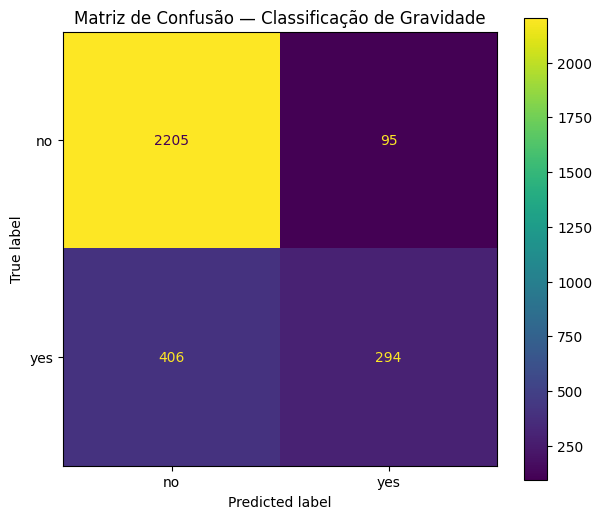

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    ax=ax,
    values_format="d"
)
plt.title("Matriz de Confusão — Classificação de Gravidade")
plt.show()


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

          no       0.84      0.96      0.90      2300
         yes       0.76      0.42      0.54       700

    accuracy                           0.83      3000
   macro avg       0.80      0.69      0.72      3000
weighted avg       0.82      0.83      0.81      3000



## Passo 12 — Limitações importantes

Mesmo com bom desempenho, este exercício tem limitações:

- os dados são **sintéticos**;
- o modelo aprende padrões de texto, não raciocínio clínico;
- desempenho em base didática não garante desempenho em ambiente real;
- em saúde, modelos devem passar por validação técnica, ética e institucional.

Este notebook é adequado para **ensino de fundamentos**, não para uso assistencial real.


## Passo 13 — Desafios para o aluno

### Desafio 1
Troque o classificador por:
- `MultinomialNB`
- ou `LinearSVC`

e compare o desempenho.

### Desafio 2
Teste diferentes configurações do `TfidfVectorizer`, como:
- apenas unigramas;
- unigramas + bigramas;
- remoção de stopwords.

### Desafio 3
Crie uma coluna com a **probabilidade da classe prevista** para cada registro do conjunto de teste.

### Desafio 4
Investigue exemplos em que o modelo errou:
- qual era a classe real?
- qual foi a classe prevista?
- que palavras podem ter confundido o modelo?


# Referências e próximos passos

Depois deste notebook, a trilha pode avançar para:
- embeddings de texto;
- classificação com LLMs;
- extração de informação clínica;
- avaliação de prompts e pipelines híbridos.

---
## Mensagem final

Você acabou de construir um classificador supervisionado para **dados textuais clínicos**.  
Esse é um passo importante entre o **tratamento de dados com Pandas** e o uso de abordagens mais avançadas em PLN.
